# Task 1

In [1]:
import time
import cProfile
import pstats
import io
import numpy as np
import pandas as pd
from functools import lru_cache
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [2]:
heart = pd.read_csv('heart.csv')
heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,Male,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,Male,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,Male,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,Male,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,Female,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
heart['sex'] = heart['sex'].map({'Male': 1, 'Female': 0})
heart.isnull().sum().sum()

np.int64(0)

In [4]:
X = heart.drop('target', axis=1)
y = heart['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
features = list(X.columns)

In [5]:
rf = RandomForestClassifier(n_estimators=500, random_state=42)
rf.fit(X_train, y_train)
accuracy_score(y_test, rf.predict(X_test))

1.0

In [6]:
def predict_baseline(payload):
    df = pd.DataFrame([payload])
    df = df[features]
    return int(rf.predict(df)[0])

In [7]:
requests = X_test.to_dict('records')
len(requests)

205

In [8]:
def measure(fn, reqs, n=200):
    times = []
    for i in range(n):
        r = reqs[i % len(reqs)]
        t0 = time.perf_counter()
        fn(r)
        times.append((time.perf_counter() - t0) * 1000)
    return np.array(times)

In [9]:
base_times = measure(predict_baseline, requests)
print('mean ms', base_times.mean().round(3))
print('p95 ms', np.percentile(base_times, 95).round(3))

mean ms 74.357
p95 ms 98.868


In [10]:
pr = cProfile.Profile()
pr.enable()
for r in requests[:100]:
    predict_baseline(r)
pr.disable()
s = io.StringIO()
pstats.Stats(pr, stream=s).sort_stats('cumulative').print_stats(8)
print(s.getvalue())

         17909268 function calls (17895066 primitive calls) in 18.406 seconds

   Ordered by: cumulative time
   List reduced from 647 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000   18.454    9.227 c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\interactiveshell.py:3712(run_code)
      3/2    0.000    0.000   18.454    9.227 {built-in method builtins.exec}
        1    0.003    0.003   18.447   18.447 C:\Users\DELL\AppData\Local\Temp\ipykernel_11388\748959621.py:1(<module>)
      100    0.002    0.000   18.444    0.184 C:\Users\DELL\AppData\Local\Temp\ipykernel_11388\518449797.py:1(predict_baseline)
      100    0.001    0.000   18.135    0.181 c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\ensemble\_forest.py:882(predict)
      100    0.005    0.000   18.133    0.181 c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-pack

In [11]:
payload = requests[0]
t0 = time.perf_counter()
for _ in range(200):
    df = pd.DataFrame([payload])[features]
t_df = (time.perf_counter() - t0) / 200 * 1000
arr = df.values
t0 = time.perf_counter()
for _ in range(200):
    rf.predict(arr)
t_pred = (time.perf_counter() - t0) / 200 * 1000
print('dataframe build ms', round(t_df, 3))
print('model predict ms', round(t_pred, 3))

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\

dataframe build ms 2.604
model predict ms 64.968


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [12]:
def predict_numpy(payload):
    x = np.array([[payload[f] for f in features]], dtype=np.float32)
    return int(rf.predict(x)[0])

In [13]:
numpy_times = measure(predict_numpy, requests)
print('mean ms', numpy_times.mean().round(3))
print('p95 ms', np.percentile(numpy_times, 95).round(3))

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\

mean ms 75.434
p95 ms 112.976


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [14]:
rf_small = RandomForestClassifier(n_estimators=60, random_state=42, n_jobs=1)
rf_small.fit(X_train, y_train)
accuracy_score(y_test, rf_small.predict(X_test))

1.0

In [15]:
def predict_small(payload):
    x = np.array([[payload[f] for f in features]], dtype=np.float32)
    return int(rf_small.predict(x)[0])

In [16]:
small_times = measure(predict_small, requests)
print('mean ms', small_times.mean().round(3))
print('p95 ms', np.percentile(small_times, 95).round(3))

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\

mean ms 8.787
p95 ms 12.255


In [17]:
scaler = StandardScaler().fit(X_train)
lr = LogisticRegression(max_iter=1000)
lr.fit(scaler.transform(X_train), y_train)
accuracy_score(y_test, lr.predict(scaler.transform(X_test)))

0.8097560975609757

In [18]:
w = lr.coef_[0]
w_scale = np.abs(w).max() / 127
w_int8 = np.round(w / w_scale).astype(np.int8)
b = lr.intercept_[0]
mean = scaler.mean_.astype(np.float32)
scale = scaler.scale_.astype(np.float32)
w_int8

array([ -17, -114,  127,  -53,  -40,   -2,   24,   60,  -76,  -90,   53,
       -109,  -73], dtype=int8)

In [19]:
def predict_quantized(payload):
    x = np.array([payload[f] for f in features], dtype=np.float32)
    z = (x - mean) / scale
    score = np.dot(z, w_int8.astype(np.float32)) * w_scale + b
    return int(score > 0)

In [20]:
q_preds = [predict_quantized(r) for r in requests]
print('quantized accuracy', accuracy_score(y_test, q_preds))
print('float accuracy', accuracy_score(y_test, lr.predict(scaler.transform(X_test))))

quantized accuracy 0.8097560975609757
float accuracy 0.8097560975609757


In [21]:
quant_times = measure(predict_quantized, requests)
print('mean ms', quant_times.mean().round(4))
print('p95 ms', np.percentile(quant_times, 95).round(4))

mean ms 0.0308
p95 ms 0.0427


In [22]:
cache = {}
def predict_cached(payload):
    key = tuple(payload[f] for f in features)
    if key in cache:
        return cache[key]
    out = predict_small(payload)
    cache[key] = out
    return out

In [23]:
for r in requests:
    predict_cached(r)
cached_times = measure(predict_cached, requests)
print('mean ms', cached_times.mean().round(4))
print('p95 ms', np.percentile(cached_times, 95).round(4))

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\

mean ms 0.0022
p95 ms 0.0024


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\

In [24]:
@lru_cache(maxsize=1024)
def predict_lru(key):
    x = np.array([key], dtype=np.float32)
    return int(rf_small.predict(x)[0])

def predict_lru_api(payload):
    return predict_lru(tuple(payload[f] for f in features))

In [25]:
lru_times = measure(predict_lru_api, requests)
print('mean ms', lru_times.mean().round(4))
print(predict_lru.cache_info())

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\

mean ms 7.275
CacheInfo(hits=48, misses=152, maxsize=1024, currsize=152)


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [26]:
summary = pd.DataFrame({
    'version': ['baseline', 'numpy input', 'smaller forest', 'int8 quantized', 'dict cache', 'lru cache'],
    'mean_ms': [base_times.mean(), numpy_times.mean(), small_times.mean(), quant_times.mean(), cached_times.mean(), lru_times.mean()],
    'p95_ms': [np.percentile(t, 95) for t in [base_times, numpy_times, small_times, quant_times, cached_times, lru_times]]
}).round(4)
summary['speedup'] = (summary['mean_ms'].iloc[0] / summary['mean_ms']).round(1)
summary

,version,mean_ms,p95_ms,speedup
0,baseline,74.3572,98.8676,1.0
1,numpy input,75.4342,112.9764,1.0
2,smaller forest,8.7872,12.2552,8.5
3,int8 quantized,0.0308,0.0427,2414.2
4,dict cache,0.0022,0.0024,33798.7
5,lru cache,7.2750,12.7115,10.2


# Task 2

In [27]:
print('PROJECT DOCUMENTATION: Heart Disease Prediction API')
print('=' * 55)
print('Dataset rows:', heart.shape[0], '| features:', len(features))

PROJECT DOCUMENTATION: Heart Disease Prediction API
Dataset rows: 1025 | features: 13


In [28]:
print('METHODOLOGY')
print('1. Loaded heart.csv and encoded sex as 0/1.')
print('2. Trained a 500 tree random forest as the baseline model.')
print('3. Profiled request-response time with perf_counter and cProfile.')
print('4. Applied numpy input, smaller forest, int8 quantization and caching.')

METHODOLOGY
1. Loaded heart.csv and encoded sex as 0/1.
2. Trained a 500 tree random forest as the baseline model.
3. Profiled request-response time with perf_counter and cProfile.
4. Applied numpy input, smaller forest, int8 quantization and caching.


In [29]:
print('EXPERIMENTAL RESULTS')
print(summary.to_string(index=False))

EXPERIMENTAL RESULTS
       version  mean_ms   p95_ms  speedup
      baseline  74.3572  98.8676      1.0
   numpy input  75.4342 112.9764      1.0
smaller forest   8.7872  12.2552      8.5
int8 quantized   0.0308   0.0427   2414.2
    dict cache   0.0022   0.0024  33798.7
     lru cache   7.2750  12.7115     10.2


In [30]:
print('MODEL QUALITY')
print('Random forest 500 trees accuracy:', round(accuracy_score(y_test, rf.predict(X_test)), 4))
print('Random forest 60 trees accuracy:', round(accuracy_score(y_test, rf_small.predict(X_test)), 4))
print('Logistic regression accuracy:', round(accuracy_score(y_test, lr.predict(scaler.transform(X_test))), 4))
print('Int8 quantized accuracy:', round(accuracy_score(y_test, q_preds), 4))

MODEL QUALITY
Random forest 500 trees accuracy: 1.0
Random forest 60 trees accuracy: 1.0
Logistic regression accuracy: 0.8098
Int8 quantized accuracy: 0.8098


In [31]:
print('LAG SOURCES FOUND')
print('DataFrame build per request (ms):', round(t_df, 3))
print('Model predict per request (ms):', round(t_pred, 3))
print('Building a DataFrame for every request added overhead on top of the model call.')

LAG SOURCES FOUND
DataFrame build per request (ms): 2.604
Model predict per request (ms): 64.968
Building a DataFrame for every request added overhead on top of the model call.


In [32]:
print('DEPLOYMENT CHALLENGES')
print('1. Large forest gives slow single request predictions.')
print('2. Quantization lowers precision and needs an accuracy check.')
print('3. Cache only helps when the same input repeats.')
print('4. Cache needs a size limit and must be cleared when the model changes.')
print('5. Dataset is small so results may not match production traffic.')

DEPLOYMENT CHALLENGES
1. Large forest gives slow single request predictions.
2. Quantization lowers precision and needs an accuracy check.
3. Cache only helps when the same input repeats.
4. Cache needs a size limit and must be cleared when the model changes.
5. Dataset is small so results may not match production traffic.


In [33]:
print('RECOMMENDATIONS')
print('1. Use numpy input and a smaller forest as the default path.')
print('2. Keep the lru cache with a fixed maxsize for repeated inputs.')
print('3. Export the model to ONNX for faster serving.')
print('4. Add request logging to track latency in production.')
print('5. Retrain on more data and re-check accuracy after every optimization.')

RECOMMENDATIONS
1. Use numpy input and a smaller forest as the default path.
2. Keep the lru cache with a fixed maxsize for repeated inputs.
3. Export the model to ONNX for faster serving.
4. Add request logging to track latency in production.
5. Retrain on more data and re-check accuracy after every optimization.


# Task 3

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
app = pd.read_csv('application_record.csv')
app.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [36]:
app.shape

(438557, 18)

In [37]:
app.info()

<class 'pandas.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  str    
 2   FLAG_OWN_CAR         438557 non-null  str    
 3   FLAG_OWN_REALTY      438557 non-null  str    
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  str    
 7   NAME_EDUCATION_TYPE  438557 non-null  str    
 8   NAME_FAMILY_STATUS   438557 non-null  str    
 9   NAME_HOUSING_TYPE    438557 non-null  str    
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL           438557 

In [38]:
app.dtypes.value_counts()

int64      8
str        8
float64    2
Name: count, dtype: int64

In [39]:
app.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,438557.0,6.022176e+06,571637.023257,5008804.0,5609375.0,6047745.0,6456971.0,7999952.0
CNT_CHILDREN,438557.0,4.273903e-01,0.724882,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,438557.0,1.875243e+05,110086.853066,26100.0,121500.0,160780.5,225000.0,6750000.0
DAYS_BIRTH,438557.0,-1.599790e+04,4185.030007,-25201.0,-19483.0,-15630.0,-12514.0,-7489.0
DAYS_EMPLOYED,438557.0,6.056368e+04,138767.799647,-17531.0,-3103.0,-1467.0,-371.0,365243.0
FLAG_MOBIL,438557.0,1.000000e+00,0.000000,1.0,1.0,1.0,1.0,1.0
FLAG_WORK_PHONE,438557.0,2.061328e-01,0.404527,0.0,0.0,0.0,0.0,1.0
FLAG_PHONE,438557.0,2.877710e-01,0.452724,0.0,0.0,0.0,1.0,1.0
FLAG_EMAIL,438557.0,1.082071e-01,0.310642,0.0,0.0,0.0,0.0,1.0
CNT_FAM_MEMBERS,438557.0,2.194465e+00,0.897207,1.0,2.0,2.0,3.0,20.0


In [40]:
app.describe(include='object').T

C:\Users\DELL\AppData\Local\Temp\ipykernel_11388\3577871124.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  app.describe(include='object').T


,count,unique,top,freq
CODE_GENDER,438557,2,F,294440
FLAG_OWN_CAR,438557,2,N,275459
FLAG_OWN_REALTY,438557,2,Y,304074
NAME_INCOME_TYPE,438557,5,Working,226104
NAME_EDUCATION_TYPE,438557,5,Secondary / secondary special,301821
NAME_FAMILY_STATUS,438557,5,Married,299828
NAME_HOUSING_TYPE,438557,6,House / apartment,393831
OCCUPATION_TYPE,304354,18,Laborers,78240


In [41]:
app.isnull().sum()

ID                          0
CODE_GENDER                 0
FLAG_OWN_CAR                0
FLAG_OWN_REALTY             0
CNT_CHILDREN                0
AMT_INCOME_TOTAL            0
NAME_INCOME_TYPE            0
NAME_EDUCATION_TYPE         0
NAME_FAMILY_STATUS          0
NAME_HOUSING_TYPE           0
DAYS_BIRTH                  0
DAYS_EMPLOYED               0
FLAG_MOBIL                  0
FLAG_WORK_PHONE             0
FLAG_PHONE                  0
FLAG_EMAIL                  0
OCCUPATION_TYPE        134203
CNT_FAM_MEMBERS             0
dtype: int64

In [42]:
(app.isnull().mean() * 100).round(2)

ID                      0.0
CODE_GENDER             0.0
FLAG_OWN_CAR            0.0
FLAG_OWN_REALTY         0.0
CNT_CHILDREN            0.0
AMT_INCOME_TOTAL        0.0
NAME_INCOME_TYPE        0.0
NAME_EDUCATION_TYPE     0.0
NAME_FAMILY_STATUS      0.0
NAME_HOUSING_TYPE       0.0
DAYS_BIRTH              0.0
DAYS_EMPLOYED           0.0
FLAG_MOBIL              0.0
FLAG_WORK_PHONE         0.0
FLAG_PHONE              0.0
FLAG_EMAIL              0.0
OCCUPATION_TYPE        30.6
CNT_FAM_MEMBERS         0.0
dtype: float64

In [43]:
app.duplicated().sum()

np.int64(0)

In [44]:
app['ID'].duplicated().sum()

np.int64(47)

In [45]:
app['ID'].nunique()

438510

In [46]:
for c in app.select_dtypes(include='object').columns:
    print(app[c].value_counts(dropna=False))
    print()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11388\4164045393.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in app.select_dtypes(include='object').columns:


CODE_GENDER
F    294440
M    144117
Name: count, dtype: int64

FLAG_OWN_CAR
N    275459
Y    163098
Name: count, dtype: int64

FLAG_OWN_REALTY
Y    304074
N    134483
Name: count, dtype: int64

NAME_INCOME_TYPE
Working                 226104
Commercial associate    100757
Pensioner                75493
State servant            36186
Student                     17
Name: count, dtype: int64

NAME_EDUCATION_TYPE
Secondary / secondary special    301821
Higher education                 117522
Incomplete higher                 14851
Lower secondary                    4051
Academic degree                     312
Name: count, dtype: int64

NAME_FAMILY_STATUS
Married                 299828
Single / not married     55271
Civil marriage           36532
Separated                27251
Widow                    19675
Name: count, dtype: int64

NAME_HOUSING_TYPE
House / apartment      393831
With parents            19077
Municipal apartment     14214
Rented apartment         5974
Office apartment     

In [47]:
app['AGE'] = (-app['DAYS_BIRTH'] / 365.25).round(1)
app['AGE'].describe()

count    438557.000000
mean         43.799839
std          11.457860
min          20.500000
25%          34.300000
50%          42.800000
75%          53.300000
max          69.000000
Name: AGE, dtype: float64

In [48]:
(app['DAYS_EMPLOYED'] > 0).sum()

np.int64(75329)

In [49]:
app.loc[app['DAYS_EMPLOYED'] > 0, 'DAYS_EMPLOYED'].unique()

array([365243])

In [50]:
app.loc[app['DAYS_EMPLOYED'] > 0, 'NAME_INCOME_TYPE'].value_counts()

NAME_INCOME_TYPE
Pensioner    75329
Name: count, dtype: int64

In [51]:
emp = app['DAYS_EMPLOYED'].where(app['DAYS_EMPLOYED'] < 0)
app['YEARS_EMPLOYED'] = (-emp / 365.25).round(1)
app['YEARS_EMPLOYED'].describe()

count    363228.000000
mean          7.181480
std           6.569644
min           0.000000
25%           2.500000
50%           5.300000
75%           9.600000
max          48.000000
Name: YEARS_EMPLOYED, dtype: float64

In [52]:
app['AMT_INCOME_TOTAL'].describe()

count    4.385570e+05
mean     1.875243e+05
std      1.100869e+05
min      2.610000e+04
25%      1.215000e+05
50%      1.607805e+05
75%      2.250000e+05
max      6.750000e+06
Name: AMT_INCOME_TOTAL, dtype: float64

In [53]:
app['AMT_INCOME_TOTAL'].quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999])

0.010     54000.0
0.250    121500.0
0.500    160780.5
0.750    225000.0
0.950    360000.0
0.990    540000.0
0.999    990000.0
Name: AMT_INCOME_TOTAL, dtype: float64

In [54]:
app['CNT_CHILDREN'].value_counts().sort_index()

CNT_CHILDREN
0     304071
1      88527
2      39884
3       5430
4        486
5        133
6          4
7          9
9          5
12         4
14         3
19         1
Name: count, dtype: int64

In [55]:
app['CNT_FAM_MEMBERS'].value_counts().sort_index()

CNT_FAM_MEMBERS
1.0      84492
2.0     233891
3.0      77128
4.0      37356
5.0       5081
6.0        459
7.0        124
8.0          4
9.0          9
11.0         5
14.0         4
15.0         3
20.0         1
Name: count, dtype: int64

In [56]:
app['FLAG_MOBIL'].value_counts()

FLAG_MOBIL
1    438557
Name: count, dtype: int64

In [57]:
def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()

for c in ['AMT_INCOME_TOTAL', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'AGE']:
    print(c, iqr_outliers(app[c]))

AMT_INCOME_TOTAL 19108
CNT_CHILDREN 6075
CNT_FAM_MEMBERS 5690
AGE 0


In [58]:
app['OCCUPATION_TYPE'].isnull().groupby(app['NAME_INCOME_TYPE']).mean().round(3)

NAME_INCOME_TYPE
Commercial associate    0.166
Pensioner               0.998
State servant           0.172
Student                 0.294
Working                 0.159
Name: OCCUPATION_TYPE, dtype: float64

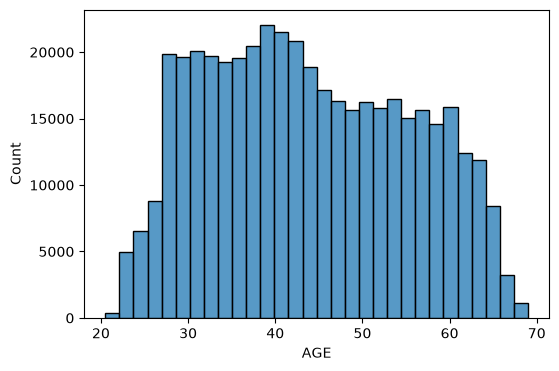

In [59]:
plt.figure(figsize=(6, 4))
sns.histplot(app['AGE'], bins=30)
plt.show()

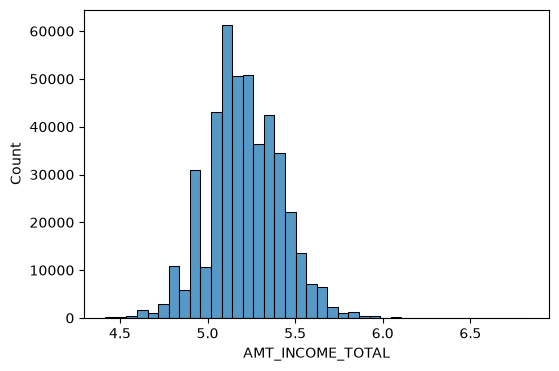

In [60]:
plt.figure(figsize=(6, 4))
sns.histplot(np.log10(app['AMT_INCOME_TOTAL']), bins=40)
plt.show()

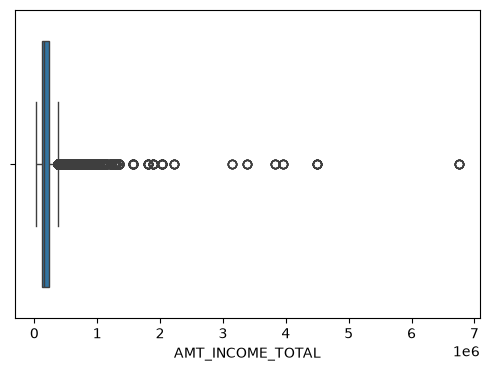

In [61]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=app['AMT_INCOME_TOTAL'])
plt.show()

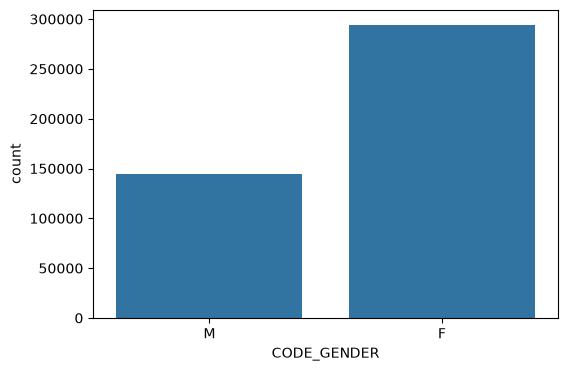

In [62]:
plt.figure(figsize=(6, 4))
sns.countplot(data=app, x='CODE_GENDER')
plt.show()

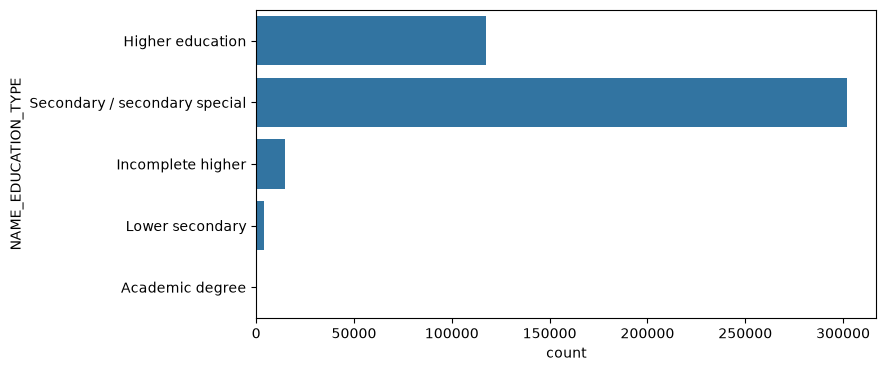

In [63]:
plt.figure(figsize=(8, 4))
sns.countplot(data=app, y='NAME_EDUCATION_TYPE')
plt.show()

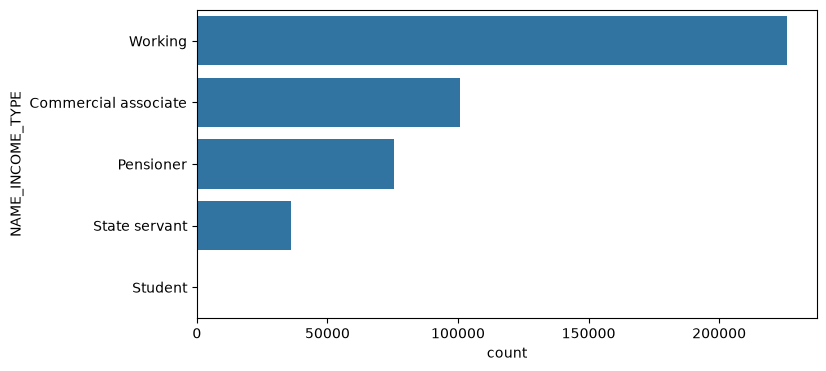

In [64]:
plt.figure(figsize=(8, 4))
sns.countplot(data=app, y='NAME_INCOME_TYPE')
plt.show()

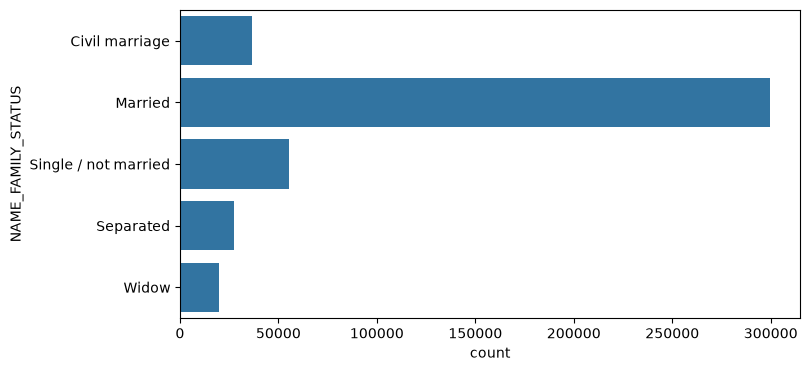

In [65]:
plt.figure(figsize=(8, 4))
sns.countplot(data=app, y='NAME_FAMILY_STATUS')
plt.show()

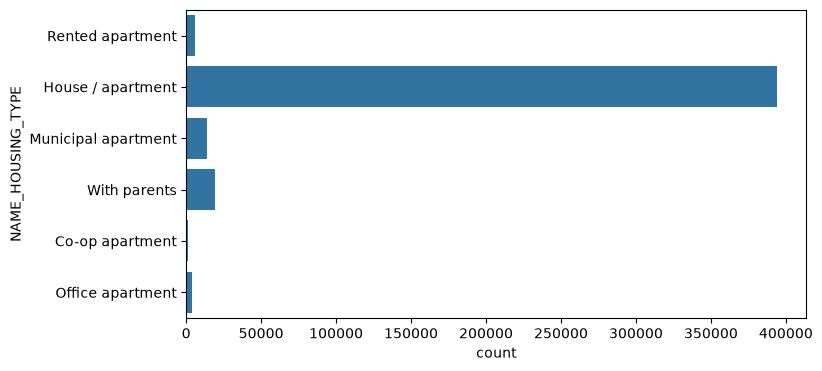

In [66]:
plt.figure(figsize=(8, 4))
sns.countplot(data=app, y='NAME_HOUSING_TYPE')
plt.show()

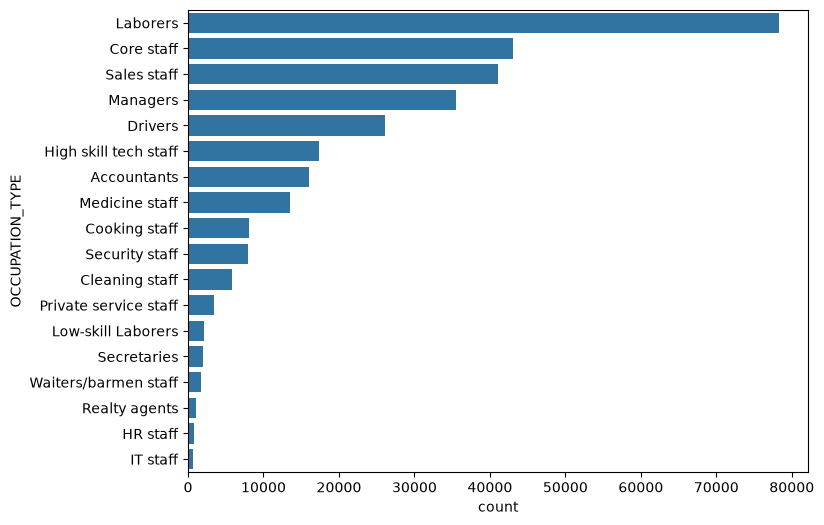

In [67]:
plt.figure(figsize=(8, 6))
sns.countplot(data=app, y='OCCUPATION_TYPE', order=app['OCCUPATION_TYPE'].value_counts().index)
plt.show()

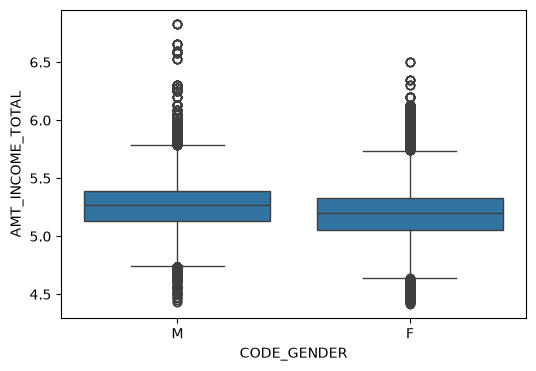

In [68]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=app, x='CODE_GENDER', y=np.log10(app['AMT_INCOME_TOTAL']))
plt.show()

In [69]:
app.groupby('NAME_EDUCATION_TYPE')['AMT_INCOME_TOTAL'].median().sort_values()

NAME_EDUCATION_TYPE
Lower secondary                  135000.0
Secondary / secondary special    157500.0
Incomplete higher                180000.0
Higher education                 202500.0
Academic degree                  225000.0
Name: AMT_INCOME_TOTAL, dtype: float64

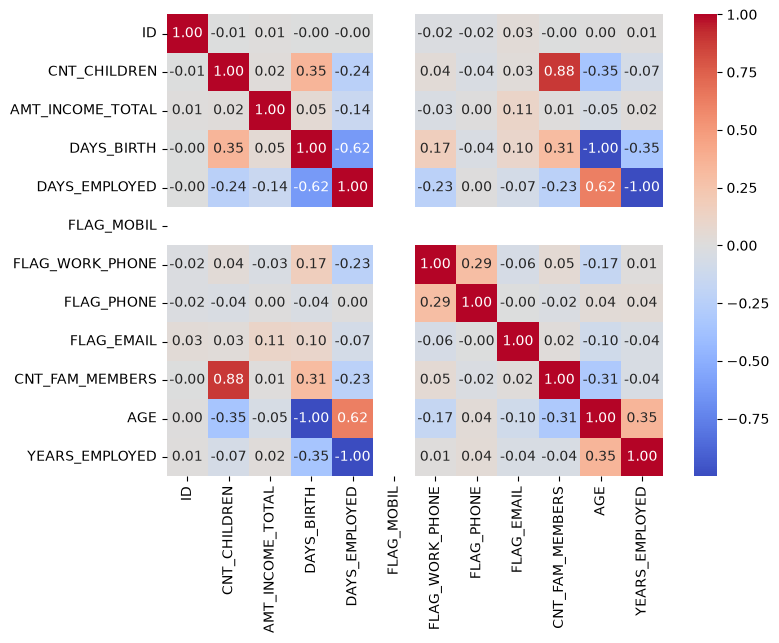

In [70]:
plt.figure(figsize=(8, 6))
sns.heatmap(app.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [71]:
pd.crosstab(app['FLAG_OWN_CAR'], app['FLAG_OWN_REALTY'], normalize='all').round(3)

FLAG_OWN_REALTY,N,Y
FLAG_OWN_CAR,,
N,0.192,0.436
Y,0.114,0.258


In [72]:
quality = pd.DataFrame({
    'missing': app.isnull().sum(),
    'missing_pct': (app.isnull().mean() * 100).round(2),
    'unique': app.nunique()
})
quality

,missing,missing_pct,unique
ID,0,0.00,438510
CODE_GENDER,0,0.00,2
FLAG_OWN_CAR,0,0.00,2
FLAG_OWN_REALTY,0,0.00,2
CNT_CHILDREN,0,0.00,12
AMT_INCOME_TOTAL,0,0.00,866
NAME_INCOME_TYPE,0,0.00,5
NAME_EDUCATION_TYPE,0,0.00,5
NAME_FAMILY_STATUS,0,0.00,5
NAME_HOUSING_TYPE,0,0.00,6


In [73]:
print('duplicate rows:', app.duplicated().sum())
print('duplicate ids:', app['ID'].duplicated().sum())
print('days employed placeholder rows:', (app['DAYS_EMPLOYED'] > 0).sum())
print('missing occupation rows:', app['OCCUPATION_TYPE'].isnull().sum())
print('constant columns:', [c for c in app.columns if app[c].nunique() == 1])

duplicate rows: 0
duplicate ids: 47
days employed placeholder rows: 75329
missing occupation rows: 134203
constant columns: ['FLAG_MOBIL']
